# NB3b — So sánh các biến thể: DPO · RPO · DPO chuẩn hoá độ dài · LD-DPO · ORPO (TUỲ CHỌN, +8)

Cùng dữ liệu (`VARIANT_TRAIN` cặp đầu của NB2), cùng số bước, cùng LoRA. Chỉ đổi loss.

| Run | Cấu hình TRL | Ý tưởng |
|---|---|---|
| `dpo` | `loss_type=["sigmoid"]` | mức cơ sở (baseline) |
| `rpo` | `loss_type=["sigmoid","sft"]` | thêm NLL trên chosen, chống likelihood displacement |
| `dpo_norm` | `loss_type=["sigmoid_norm"]` | log-prob trung bình theo token (gần SimPO nhưng vẫn có reference) |
| `ld_dpo` | `ld_alpha=0.5` | giảm trọng số phần token vượt quá độ dài chung (LD-DPO) |
| `orpo` | `trl.experimental.orpo` | không reference, SFT + odds-ratio trong một bước |

ORPO thường xuất phát từ mô hình *chưa* SFT; ở đây nó chạy trên cùng `models/sft-merged`
để bảng so sánh chỉ khác nhau ở loss. Đặt `ORPO_FROM_BASE=1` để thử ORPO từ base.

**Đọc kết quả:** độ chính xác reward trên held-out và độ dài đầu ra trung bình. Các
biến thể có thang reward khác nhau, nên **không so trực tiếp giá trị margin** giữa các dòng.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lab22" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import unsloth  # noqa: F401
import torch

from lab22 import config as C
from lab22 import modeling as MD

assert torch.cuda.is_available()
assert C.SFT_MERGED.exists() and (C.PREF_DIR / "train.parquet").exists(), "Run NB1 + NB2 first"

from datasets import Dataset

train_ds = Dataset.from_parquet(str(C.PREF_DIR / "train.parquet"))
train_ds = train_ds.select(range(min(C.TIER.variant_train, len(train_ds))))
assert len(train_ds) > 0, "Empty preference train split: rerun NB2"
eval_ds = Dataset.from_parquet(str(C.PREF_DIR / "eval.parquet"))
probe_prompts = [r["prompt"][0]["content"] for r in eval_ds.select(range(min(20, len(eval_ds))))]
print(f"variant train={len(train_ds)} eval={len(eval_ds)} probe prompts={len(probe_prompts)}")

RUNS = {
    "dpo": {"loss_type": ["sigmoid"]},
    "rpo": {"loss_type": ["sigmoid", "sft"], "loss_weights": [1.0, 1.0]},
    "dpo_norm": {"loss_type": ["sigmoid_norm"]},
    "ld_dpo": {"loss_type": ["sigmoid"], "ld_alpha": 0.5},
}
SELECTED = [r for r in os.environ.get("VARIANTS", "dpo,rpo,dpo_norm,ld_dpo,orpo").split(",") if r]

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


D:\Day22\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1023 02:28:51.517000 27452 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Unsloth: xformers is installed but cannot load with torch 2.10.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
variant train=300 eval=100 probe prompts=20


## 1. Các biến thể dựa trên DPOTrainer

In [2]:
import json

from trl import DPOTrainer

results = {}
for name in [r for r in SELECTED if r in RUNS]:
    print(f"\n=== {name} ===")
    model, tokenizer = MD.load_model(C.SFT_MERGED)
    model = MD.add_lora(model)
    overrides = dict(RUNS[name])
    loss_type = overrides.pop("loss_type")
    trainer = DPOTrainer(
        model=model,
        args=MD.dpo_config(C.VARIANTS_DIR / f"{name}-ckpt", loss_type=loss_type, eval_strategy="no", **overrides),
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
    )
    trainer.train()
    ev = trainer.evaluate()
    outputs = MD.generate(trainer.model, tokenizer, probe_prompts, max_new_tokens=256)
    results[name] = {
        "eval_reward_accuracy": ev.get("eval_rewards/accuracies"),
        "eval_chosen_reward": ev.get("eval_rewards/chosen"),
        "eval_rejected_reward": ev.get("eval_rewards/rejected"),
        "mean_output_chars": sum(map(len, outputs)) / len(outputs),
        "diagnosis": MD.diagnose(MD.reward_history(trainer.state.log_history))[0],
    }
    trainer.model.save_pretrained(str(C.VARIANTS_DIR / name))
    print(results[name])
    del trainer, model
    MD.cleanup()


=== dpo ===
==((====))==  Unsloth 2026.10.7: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 3060. Num GPUs = 1. Max memory: 12.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.10.0+cu130. CUDA: 8.6. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights: 100%|██████████| 398/398 [00:10<00:00, 38.79it/s]
Unsloth 2026.10.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: `eval_steps = 25` is ignored because `eval_strategy` is 'no'. Set `eval_strategy = "steps"` to evaluate every `eval_steps` steps.


Computing reference log probs for train dataset:   0%|          | 0/300 [00:00<?, ?it/s]

Unsloth: Will smartly offload gradients to save VRAM!


...

Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,rewards / chosen,rewards / rejected,rewards / accuracies,rewards / margins,logits / chosen,logits / rejected,logps / chosen,logps / rejected
5,0.696021,0.002513,0.005010,0.450000,-0.002497,-1.805169,-1.682091,-276.421742,-247.156149
10,0.690971,0.000014,-0.008338,0.525000,0.008352,-1.986166,-1.906280,-307.281110,-282.108376
15,0.698645,-0.040461,-0.035091,0.600000,-0.005370,-2.222663,-2.082828,-317.867109,-311.622787
20,0.678181,-0.000626,-0.038581,0.600000,0.037955,-2.193960,-1.814132,-327.321887,-314.679562
25,0.697796,-0.033272,-0.037897,0.600000,0.004626,-1.970732,-1.962498,-358.967093,-372.538349
30,0.687471,-0.067794,-0.082983,0.550000,0.015189,-1.939798,-1.951846,-247.840442,-234.479830
35,0.698847,-0.058867,-0.052643,0.450000,-0.006224,-1.945920,-1.930936,-292.863674,-284.385805


Training Loss,Validation Loss,Step,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
0.698847,0.690002,38,1.504057,212004.000000,-2.085450,-2.081373,0.617288,-0.064213,-0.076062,0.600000,0.011849,-340.604632,-319.701871


Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'eval_reward_accuracy': 0.6, 'eval_chosen_reward': -0.06421315288869664, 'eval_rejected_reward': -0.07606214698549593, 'mean_output_chars': 447.75, 'diagnosis': 'LIKELIHOOD DISPLACEMENT'}


## 2. ORPO (không reference)

In [3]:
if "orpo" in SELECTED:
    from trl.experimental.orpo import ORPOConfig, ORPOTrainer

    start = C.BASE_MODEL if os.environ.get("ORPO_FROM_BASE") == "1" else C.SFT_MERGED
    model, tokenizer = MD.load_model(start)
    model = MD.add_lora(model)
    orpo_args = ORPOConfig(
        output_dir=str(C.VARIANTS_DIR / "orpo-ckpt"),
        per_device_train_batch_size=C.TIER.dpo_batch,
        per_device_eval_batch_size=C.TIER.dpo_batch,
        gradient_accumulation_steps=C.TIER.dpo_grad_accum,
        num_train_epochs=C.DPO_EPOCHS,
        learning_rate=C.DPO_LR,
        beta=0.1,  # λ in the paper
        max_length=C.MAX_LEN,
        warmup_steps=0.1,
        lr_scheduler_type="cosine",
        logging_steps=5,
        save_strategy="no",
        optim="adamw_8bit",
        seed=C.SEED,
        report_to="none",
        **MD.precision_flags(),
    )
    trainer = ORPOTrainer(
        model=model, args=orpo_args, train_dataset=train_ds, eval_dataset=eval_ds, processing_class=tokenizer
    )
    trainer.train()
    ev = trainer.evaluate()
    outputs = MD.generate(trainer.model, tokenizer, probe_prompts, max_new_tokens=256)
    results["orpo"] = {
        "start": str(start),
        "eval_reward_accuracy": ev.get("eval_rewards/accuracies"),
        "eval_log_odds_ratio": ev.get("eval_log_odds_ratio"),
        "mean_output_chars": sum(map(len, outputs)) / len(outputs),
    }
    trainer.model.save_pretrained(str(C.VARIANTS_DIR / "orpo"))
    print(results["orpo"])
    del trainer, model
    MD.cleanup()

==((====))==  Unsloth 2026.10.7: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 3060. Num GPUs = 1. Max memory: 12.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.10.0+cu130. CUDA: 8.6. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights: 100%|██████████| 398/398 [00:10<00:00, 38.69it/s]
[trl.experimental.orpo.orpo_trainer|WARNING][RANK 0] When using DPODataCollatorWithPadding, you should set `remove_unused_columns=False` in your TrainingArguments we have set it for you, but you should do it yourself in the future.


Unsloth for ORPO_TRAINER is not yet implemented! Just ignore this function.
We support: `['base_trainer', 'distillation_trainer', 'dpo_trainer', 'grpo_trainer', 'kto_trainer', 'reward_trainer', 'rloo_trainer', 'sft_trainer']`


Map: 100%|██████████| 100/100 [00:00<00:00, 225.60 examples/s]
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 300 | Num Epochs = 1 | Total steps = 38
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 33,030,144 of 4,055,498,240 (0.81% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,rewards / chosen,rewards / rejected,rewards / accuracies,rewards / margins,logits / chosen,logits / rejected,logps / chosen,logps / rejected
5,2.185462,-0.172036,-0.195175,0.725000,0.023140,-2.342169,-2.084073,-1.720356,-1.951754
10,2.156802,-0.183147,-0.200105,0.725000,0.016958,-2.650399,-2.378639,-1.831468,-2.001049
15,2.369086,-0.184038,-0.206120,0.775000,0.022082,-2.632232,-2.342405,-1.840379,-2.061200
20,2.300742,-0.181711,-0.209567,0.650000,0.027856,-2.543548,-2.345829,-1.817113,-2.095670
25,2.154829,-0.167898,-0.199050,0.725000,0.031152,-2.631045,-2.405799,-1.678979,-1.990496
30,2.043106,-0.166094,-0.174221,0.600000,0.008127,-2.602426,-2.475043,-1.660943,-1.742208
35,2.205701,-0.179046,-0.195374,0.650000,0.016328,-2.481030,-2.387084,-1.790457,-1.953739


Training Loss,Validation Loss,Step,Runtime,Samples Per Second,Steps Per Second,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/rejected,Logps/chosen,Logits/rejected,Logits/chosen,Nll Loss,Log Odds Ratio,Log Odds Chosen
2.205701,2.195020,38,43.915100,2.277000,2.277000,-0.178341,-0.194206,0.650000,0.015866,-1.942063,-1.783406,-2.650723,-2.631722,2.132821,-0.621994,0.185520


Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'start': 'D:\\Day22\\models\\sft-merged', 'eval_reward_accuracy': 0.6499999761581421, 'eval_log_odds_ratio': -0.6219938397407532, 'mean_output_chars': 446.7}


## 3. Bảng tổng hợp (sản phẩm nộp `03b-variants.png`)

         eval_reward_accuracy eval_chosen_reward eval_rejected_reward mean_output_chars                diagnosis                       start eval_log_odds_ratio
dpo                      0.56           0.049883             0.029968             442.9                 INTENDED                         NaN                 NaN
rpo                      0.54            0.24501              0.23443            458.55                 INTENDED                         NaN                 NaN
dpo_norm                 0.57          -0.079848            -0.098147            437.85  LIKELIHOOD DISPLACEMENT                         NaN                 NaN
ld_dpo                    0.6          -0.064213            -0.076062            447.75  LIKELIHOOD DISPLACEMENT                         NaN                 NaN
orpo                     0.65                NaN                  NaN             446.7                      NaN  D:\Day22\models\sft-merged           -0.621994


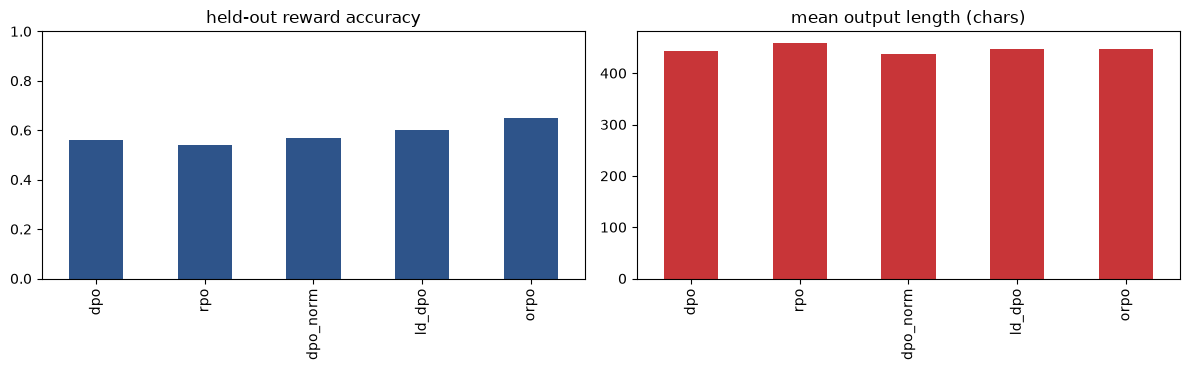

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

table = pd.DataFrame(results).T
print(table.to_string())
(C.VARIANTS_DIR / "variants_summary.json").write_text(json.dumps(results, indent=2, default=str))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
table["eval_reward_accuracy"].astype(float).plot.bar(ax=axes[0], color="#2e548a")
axes[0].set_ylim(0, 1)
axes[0].set_title("held-out reward accuracy")
table["mean_output_chars"].astype(float).plot.bar(ax=axes[1], color="#c83538")
axes[1].set_title("mean output length (chars)")
fig.tight_layout()
fig.savefig(C.SCREENSHOTS / "03b-variants.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Câu hỏi cho REFLECTION

1. Biến thể nào làm đầu ra dài ra nhiều nhất? Có khớp với tỉ lệ "chosen dài hơn" ở NB2 không?
2. RPO có giữ `rewards/chosen` dương trong khi DPO thì không? (so với chẩn đoán NB3)
3. Độ chính xác reward cao hơn có nghĩa là mô hình tốt hơn không? Chạy giám khảo ở NB4 trên
   adapter `adapters/variants/<name>` (đặt `DPO_ADAPTER_OVERRIDE`) để kiểm tra.